### Objective

1. What does the distribution of global Spotify hits look like?
2. How long do songs typically remain on the chart?
3. What separates Top-10 songs from other charting songs?
4. How does peak position relate to streams and longevity?
5. Which artists have the largest presence?
6. How concentrated is global chart sucess among artists?
7. Which variables are strongly associated with total streams?
8. How do extreme hits differ from typical songs?
9. Are songs with lyrics available systematically different?
10. What initial insights should guide NLP and ML?

### Title and Introduction

### Exploratory Data Analysis

This notebook explores the cleaned Spotify Global Weekly Chart dataset to understand the characteristics of global chart success, longevity, peak performance, streaming volume, artist concentration and lyric availability.

The analysis focuses on descriptive and exploratory insights.

### Key Questions

1. How are chart weeks distributed?
2. How common are Top-10 appearances?
3. How does peak chart position relate to streaming performance?
4. What is relationship between chart longevity and total streams?
5. Which artists have the highest representation?
6. How concentrated is chart success across artists?
7. How do Top-10 and non-Top-10 songs differ?
8. Which numerical variables are associated with total streams?
9. How do extreme-performing songs differ from typical songs?
10. What hypotheses should be investigated in later NLP and ML notebooks?

> Important:
> Lifetime aggregate variables such as 'wks', 't10', 'PkStreams' and 'total'
> describe completed chart performance. They should not automatically be used 
> together as predictors of one another in predictive modeling because this can
> introduce target leakage.



In [2]:
# Import Libraries 

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Define Project Paths

PROJECT_ROOT = Path("..")

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_global_chart_totals_lyrics_cleaned.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
)

print("Data path:")
print(DATA_PATH)

print("\nOutput directory:")
print(OUTPUT_DIR)

Data path:
..\data\processed\spotify_global_chart_totals_lyrics_cleaned.csv

Output directory:
..\outputs\figures


In [4]:
# Load the processed dataset

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (8058, 29)


In [5]:
# Initial dataset inspection

display(df.head())

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

,artist and title,wks,t10,pk,PkStreams,total,artist name,song name,lyrics,peak_duration,artist_song_key,artist_song_key_normalized,wks_outlier,t10_outlier,PkStreams_outlier,total_outlier,extreme_performance_count,log_total,log_wks,log_PkStreams,log_t10,lyrics_original,lyrics_available,lyrics_clean,lyrics_char_count,lyrics_word_count,lyrics_line_count,words_per_line,top10_reached
0,The Weeknd - Blinding Lights,347,64,1,52375259,5441240333,The Weeknd,Blinding Lights,Yeah I've been tryna call I've been on my own ...,13.0,The Weeknd | Blinding Lights,the weeknd | blinding lights,True,True,True,True,4,22.417273,5.852202,17.773945,4.174387,Yeah I've been tryna call I've been on my own ...,True,Yeah I've been tryna call I've been on my own ...,1230,259,1,259.0,1
1,Ed Sheeran - Shape of You,424,34,1,64217796,4470842634,Ed Sheeran,Shape of You,The club isn't the best place to find a lover ...,14.0,Ed Sheeran | Shape of You,ed sheeran | shape of you,True,True,True,True,4,22.220843,6.052089,17.977791,3.555348,The club isn't the best place to find a lover ...,True,The club isn't the best place to find a lover ...,3139,688,1,688.0,1
2,Harry Styles - As It Was,218,60,1,78460903,4417264164,Harry Styles,As It Was,﻿ As It Was - Harry Styles Come on Harry we wa...,11.0,Harry Styles | As It Was,harry styles | as it was,True,True,True,True,4,22.208786,5.389072,18.178111,4.110874,﻿ As It Was - Harry Styles Come on Harry we wa...,True,﻿ As It Was - Harry Styles Come on Harry we wa...,1143,243,1,243.0,1
3,The Neighbourhood - Sweater Weather,333,0,16,21624450,4142643719,The Neighbourhood,Sweater Weather,And all I am is a man I want the world in my h...,NaN,The Neighbourhood | Sweater Weather,the neighbourhood | sweater weather,True,False,False,True,2,22.144600,5.811141,16.889335,NaN,And all I am is a man I want the world in my h...,True,And all I am is a man I want the world in my h...,1678,345,1,345.0,0
4,Lewis Capaldi - Someone You Loved,343,15,4,24962682,3933581891,Lewis Capaldi,Someone You Loved,I'm going under and this time I fear there's n...,NaN,Lewis Capaldi | Someone You Loved,lewis capaldi | someone you loved,True,False,False,True,2,22.092816,5.840642,17.032893,2.772589,I'm going under and this time I fear there's n...,True,I'm going under and this time I fear there's n...,1555,323,1,323.0,1



Shape:
(8058, 29)

Columns:
['artist and title', 'wks', 't10', 'pk', 'PkStreams', 'total', 'artist name', 'song name', 'lyrics', 'peak_duration', 'artist_song_key', 'artist_song_key_normalized', 'wks_outlier', 't10_outlier', 'PkStreams_outlier', 'total_outlier', 'extreme_performance_count', 'log_total', 'log_wks', 'log_PkStreams', 'log_t10', 'lyrics_original', 'lyrics_available', 'lyrics_clean', 'lyrics_char_count', 'lyrics_word_count', 'lyrics_line_count', 'words_per_line', 'top10_reached']


In [6]:
# Data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   artist and title            8058 non-null   str    
 1   wks                         8058 non-null   int64  
 2   t10                         8058 non-null   int64  
 3   pk                          8058 non-null   int64  
 4   PkStreams                   8058 non-null   int64  
 5   total                       8058 non-null   int64  
 6   artist name                 8056 non-null   str    
 7   song name                   8058 non-null   str    
 8   lyrics                      8043 non-null   str    
 9   peak_duration               334 non-null    float64
 10  artist_song_key             8056 non-null   str    
 11  artist_song_key_normalized  8056 non-null   str    
 12  wks_outlier                 8058 non-null   bool   
 13  t10_outlier                 8058 non-null   

In [7]:
# Dataset-level summary

eda_summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Unique Songs",
        "Unique Artists",
        "Exact Duplicate Rows",
        "Lyrics Available",
        "Lyrics Unavailable",
        "Top-10 Songs",
        "Non-Top-10 Songs"
    ],

    "Value": [
        len(df),
        df.shape[1],
        df["song name"].nunique(),
        df["artist name"].nunique(),
        df.duplicated().sum(),
        df["lyrics_available"].sum(),
        (~df["lyrics_available"]).sum(),
        df["top10_reached"].sum(),
        (df["top10_reached"]== 0).sum()
    ]
})

display(eda_summary)

,Metric,Value
0,Rows,8058
1,Columns,29
2,Unique Songs,7277
3,Unique Artists,1793
4,Exact Duplicate Rows,0
5,Lyrics Available,8043
6,Lyrics Unavailable,15
7,Top-10 Songs,810
8,Non-Top-10 Songs,7248


In [8]:
# Descriptive Statistics

performance_cols = [
    "wks",
    "t10",
    "pk",
    "PkStreams",
    "total"
]

performance_stats = (
    df[performance_cols]
    .describe()
    .T
)

performance_stats["skewness"] = (
    df[performance_cols]
    .skew()
)


display(performance_stats)

,count,mean,std,min,25%,50%,75%,max,skewness
wks,8058.0,1.551055e+01,3.092141e+01,1.0,1.00,4.0,1.700000e+01,4.570000e+02,5.667378
t10,8058.0,8.252668e-01,3.768298e+00,0.0,0.00,0.0,0.000000e+00,7.100000e+01,7.157159
pk,8058.0,8.366418e+01,6.012591e+01,1.0,30.00,74.0,1.320000e+02,2.460000e+02,0.396534
PkStreams,8058.0,1.156726e+07,1.025781e+07,166910.0,5368127.50,8941469.5,1.414555e+07,1.288961e+08,2.968383
total,8058.0,1.419280e+08,3.394366e+08,166910.0,8916825.25,27980926.5,1.188043e+08,5.441240e+09,5.775126


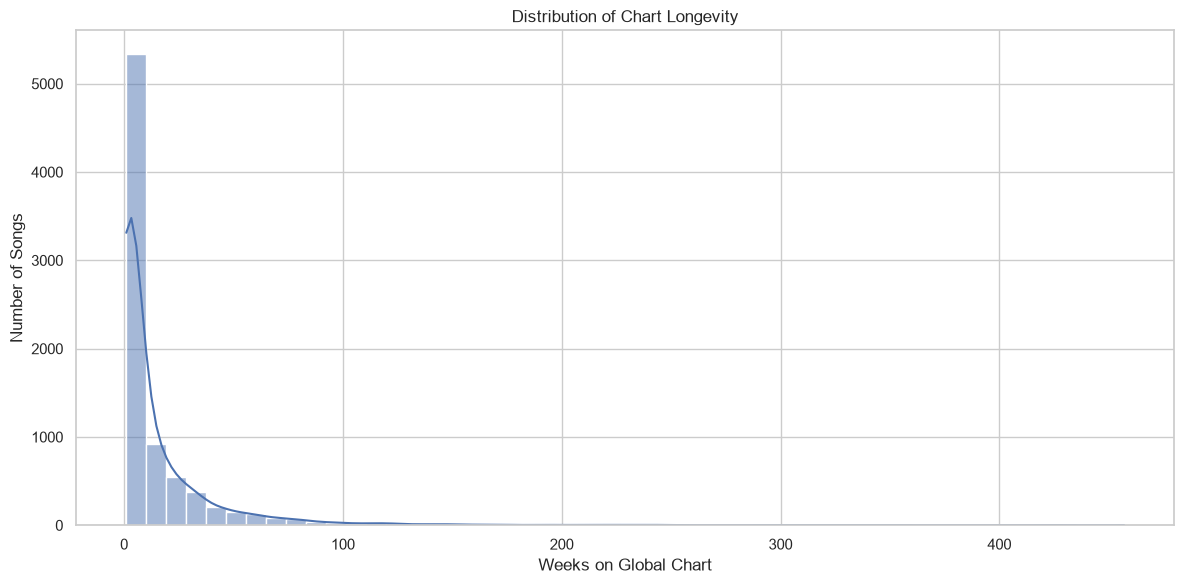

In [9]:
# 8 . Distribution of chart weeks

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="wks",
    bins=50,
    kde=True 
)


plt.title("Distribution of Chart Longevity")
plt.xlabel("Weeks on Global Chart")
plt.ylabel("Number of Songs")

plt.tight_layout()
plt.show()

Business Interpretation

The distribution will show whether the Spotify chart is dominated by short-lived songs with a smaller group of long-running hits.

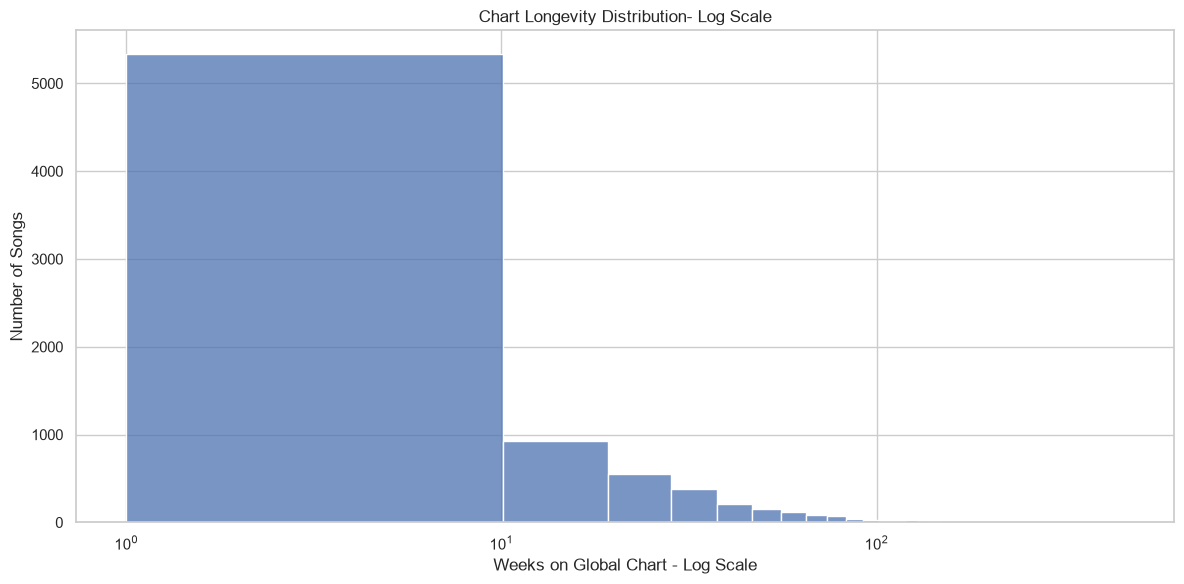

In [10]:
# Log-scale chart longevity
# Because the distribution is heavily skewed, also visualize it on a logarithmic x-axis

# 8. LOG-SCALE DISTRIBUTION OF WEEKS

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="wks",
    bins=50
)

plt.xscale("log")

plt.title("Chart Longevity Distribution- Log Scale")
plt.xlabel("Weeks on Global Chart - Log Scale")
plt.ylabel("Number of Songs")

plt.tight_layout()
plt.show()

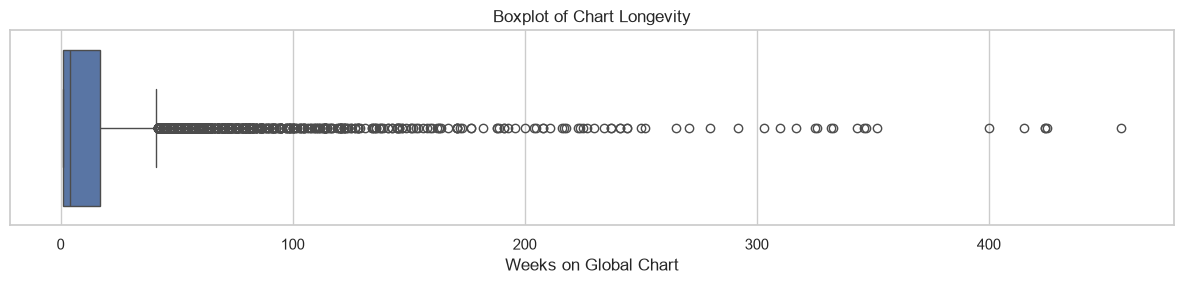

In [11]:
# 10. Chart Longevity boxplot

plt.figure(figsize=(12, 3))

sns.boxplot(
    x=df["wks"]
)

plt.title("Boxplot of Chart Longevity")
plt.xlabel("Weeks on Global Chart")

plt.tight_layout()
plt.show()

In [14]:
# 11. Songs by longevity cetagory - Create useful business-freindly categories

def longevity_category(weeks):

    if weeks <= 4:
        return "1-4 weeks"

    elif weeks <= 12:
        return "5-12 weeks"

    elif weeks <= 26:
        return "13-26 weeks"

    elif weeks <= 52:
        return "27-52 weeks"

    else:
        return "53+ weeks"

df["longevity_category"] = (
    df["wks"]
    .apply(longevity_category)
)

longevity_counts = (
    df["longevity_category"]
    .value_counts()
)


display(longevity_counts)

longevity_category
1-4 weeks      4080
5-12 weeks     1501
13-26 weeks    1113
27-52 weeks     802
53+ weeks       562
Name: count, dtype: int64

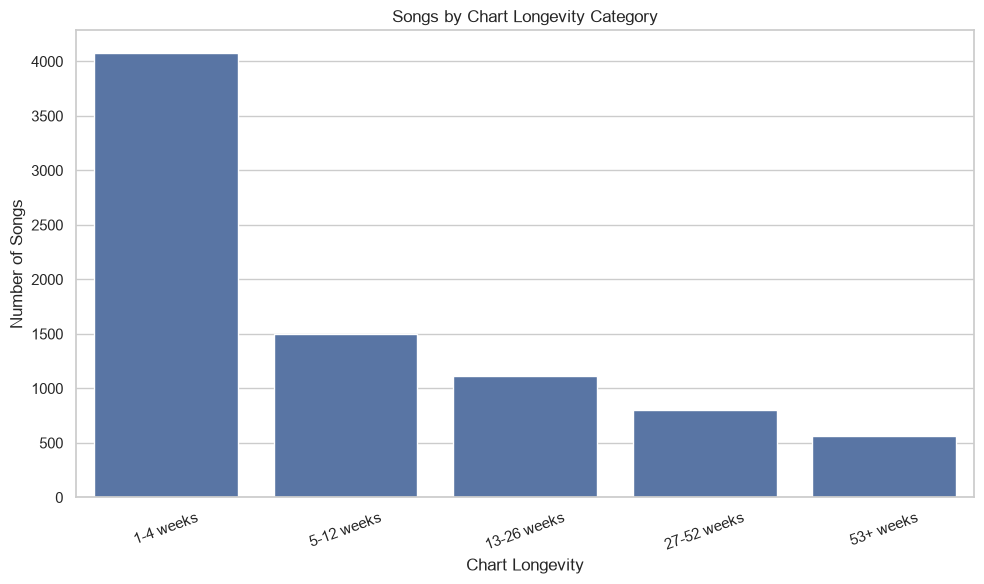

In [15]:
# Visualize

plt.figure(figsize=(10, 6))

order = [
    "1-4 weeks",
    "5-12 weeks",
    "13-26 weeks",
    "27-52 weeks",
    "53+ weeks"
]

sns.countplot(
    data=df,
    x="longevity_category",
    order=order 
)

plt.title("Songs by Chart Longevity Category")
plt.xlabel("Chart Longevity")
plt.ylabel("Number of Songs")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [16]:
# Top-10 vs non-Top-10 distribution

top10_counts = (
    df["top10_reached"]
    .map({
        0: "Did not reach Top 10",
        1: "Reached Top 10"
    })
    .value_counts()
)

display(top10_counts)

top10_reached
Did not reach Top 10    7248
Reached Top 10           810
Name: count, dtype: int64

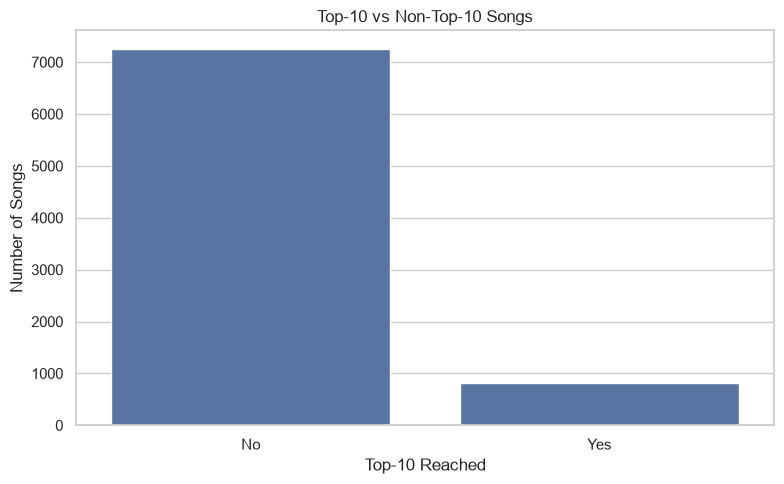

In [17]:
# Plot

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="top10_reached"
)

plt.title("Top-10 vs Non-Top-10 Songs")
plt.xlabel("Top-10 Reached")
plt.ylabel("Number of Songs")

plt.xticks(
    [0, 1],
    ["No", "Yes"]
)

plt.tight_layout()
plt.show()

In [18]:
# Top-10 percentage

top10_percentage = (
    df["top10_reached"].mean() * 100
)

print(
    f"Percentage of songs reaching the Top 10: "
    f"{top10_percentage:.2f}%"
)

Percentage of songs reaching the Top 10: 10.05%


In [20]:
# 14. Compare Top-10 and non-Top-10 songs

# TOP-10 PERFORMANCE COMPARISON

top10_comparison = (
    df.groupby("top10_reached")[
        ["wks", "PkStreams", "total", "pk"]
    ]
    .agg(
        ["count", "mean", "median"]
    )
)

display(top10_comparison)

wks                   PkStreams                            \
              count       mean median     count          mean      median   
top10_reached                                                               
0              7248  10.986203    3.0      7248  9.296212e+06   8325402.0   
1               810  55.995062   44.0       810  3.188895e+07  28690398.5   

              total                               pk                    
              count          mean       median count       mean median  
top10_reached                                                           
0              7248  8.293909e+07   21921941.5  7248  92.476545   84.0  
1               810  6.697698e+08  475375574.5   810   4.809877    4.0

In [22]:
# A cleaner version

top10_summary = (
    df.groupby("top10_reached")
    .agg(
        songs=("song name", "count"),
        median_weeks=("wks", "median"),
        mean_weeks=("wks", "mean"),
        median_peak_streams=("PkStreams","median"),
        median_total_streams=("total", "median"),
        median_peak_position=("pk", "median")
    )
)

top10_summary.index = [
    "Did not Reach Top 10",
    "Reached Top 10"
]

display(top10_summary)

,songs,median_weeks,mean_weeks,median_peak_streams,median_total_streams,median_peak_position
Did not Reach Top 10,7248,3.0,10.986203,8325402.0,21921941.5,84.0
Reached Top 10,810,44.0,55.995062,28690398.5,475375574.5,4.0


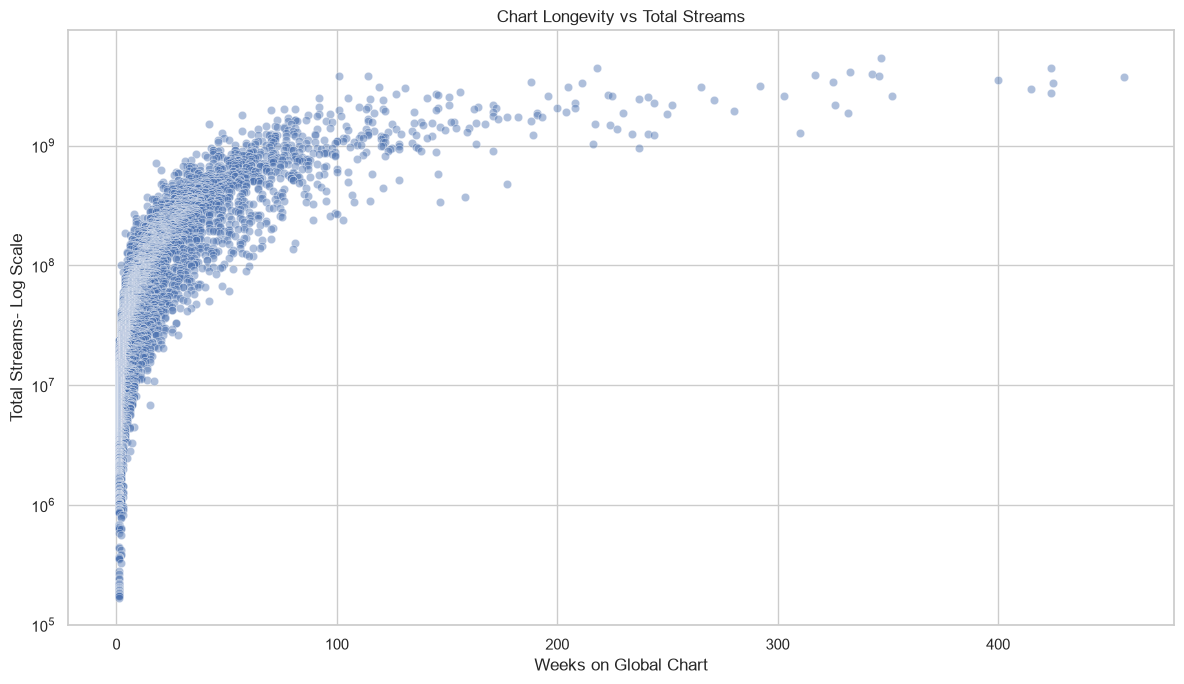

In [23]:
# 15. Chart Longevity vs total streams 

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="wks",
    y="total",
    alpha=0.45
)

plt.yscale("log")

plt.title("Chart Longevity vs Total Streams")
plt.xlabel("Weeks on Global Chart")
plt.ylabel("Total Streams- Log Scale")

plt.tight_layout()
plt.show()

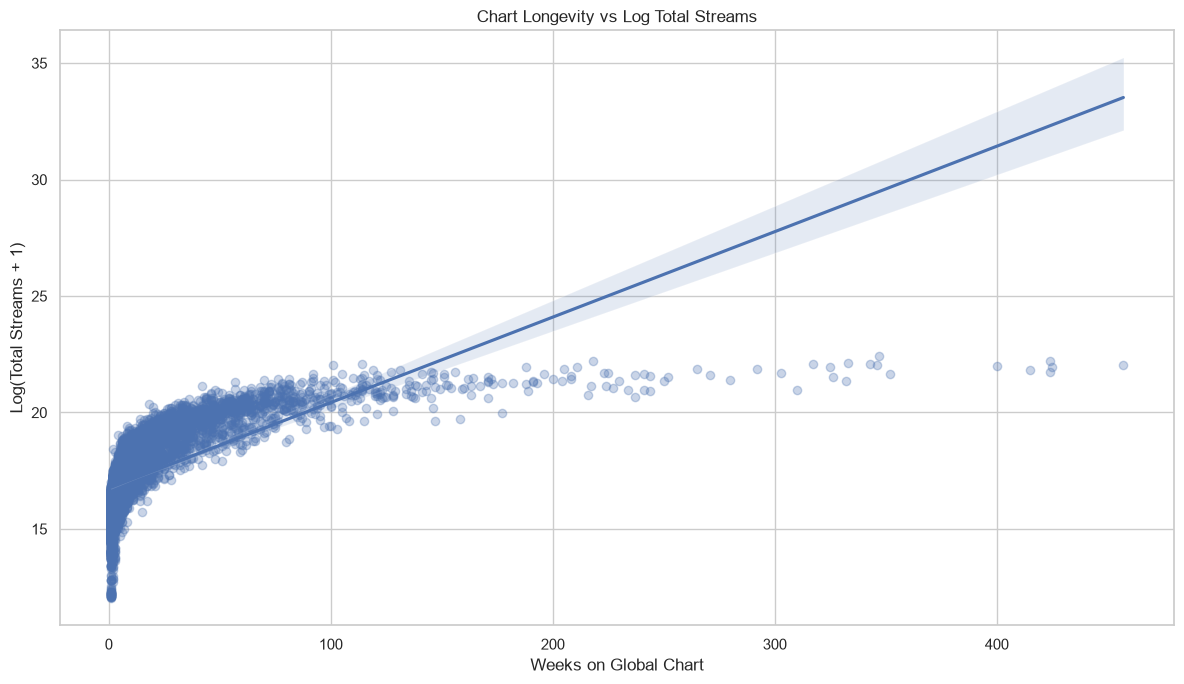

In [24]:
# 16. Add a Trend Line

plt.figure(figsize=(12, 7))

sns.regplot(
    data=df,
    x="wks",
    y="log_total",
    scatter_kws={"alpha":0.3},
    line_kws={}
)

plt.title("Chart Longevity vs Log Total Streams")
plt.xlabel("Weeks on Global Chart")
plt.ylabel("Log(Total Streams + 1)")

plt.tight_layout()
plt.show()

Using log_total reduces the visual dominance of mega-hits.

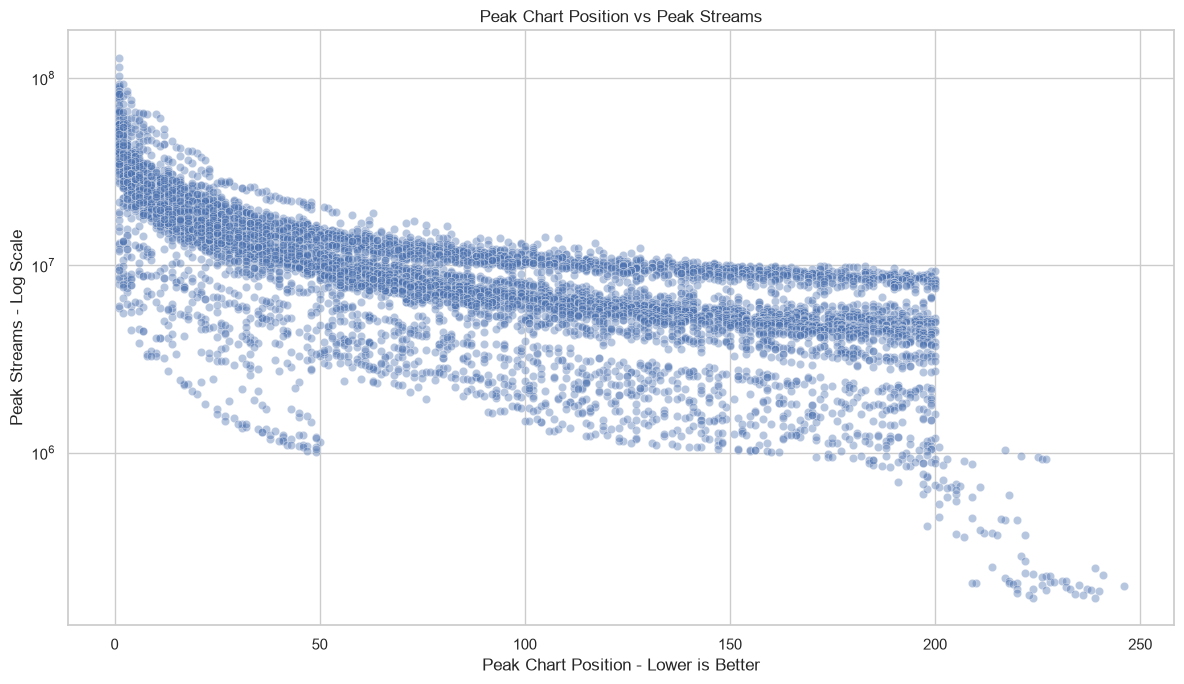

In [25]:
# 17. Peak position vs peak streams
# Lower pk means a better peak chart position

# PEAK POSITION VS PEAK STATUS

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="pk",
    y="PkStreams",
    alpha=0.4
)


plt.yscale("log")

plt.title("Peak Chart Position vs Peak Streams")
plt.xlabel("Peak Chart Position - Lower is Better")
plt.ylabel("Peak Streams - Log Scale")

plt.tight_layout()
plt.show()

The previous correlation was approximately pk vs PkStreams = -0.63

So better peak positions tend to be associated with higher peak streams in the dataset.

This is an association, not evidence that one causes the other.

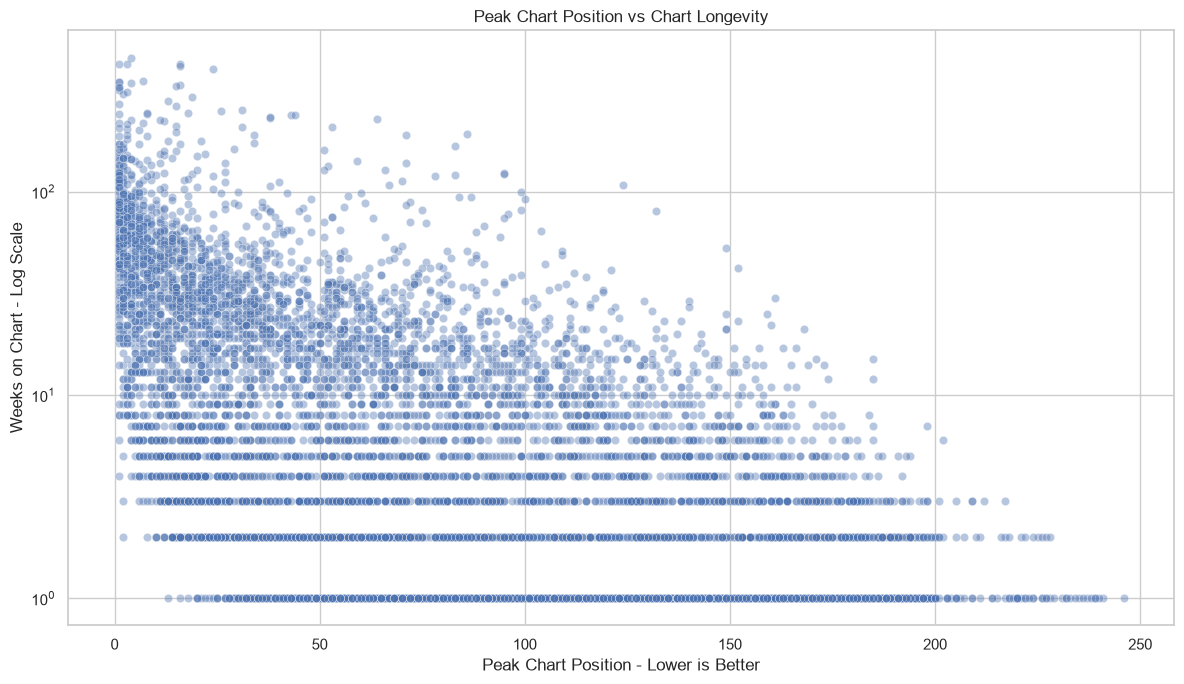

In [26]:
# 18. Peak position vs chart longevity

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="pk",
    y="wks",
    alpha=0.4
)

plt.yscale("log")

plt.title("Peak Chart Position vs Chart Longevity")
plt.xlabel("Peak Chart Position - Lower is Better")
plt.ylabel("Weeks on Chart - Log Scale")

plt.tight_layout()
plt.show()

In [27]:
# 19. Correlation mix

corr_cols = [
    "wks",
    "t10",
    "pk",
    "PkStreams",
    "total"
]

correlation_matrix = (
    df[corr_cols]
    .corr()
)


display(correlation_matrix)

,wks,t10,pk,PkStreams,total
wks,1.000000,0.535191,-0.404503,0.383219,0.892997
t10,0.535191,1.000000,-0.294015,0.549649,0.700117
pk,-0.404503,-0.294015,1.000000,-0.625544,-0.404161
PkStreams,0.383219,0.549649,-0.625544,1.000000,0.588607
total,0.892997,0.700117,-0.404161,0.588607,1.000000


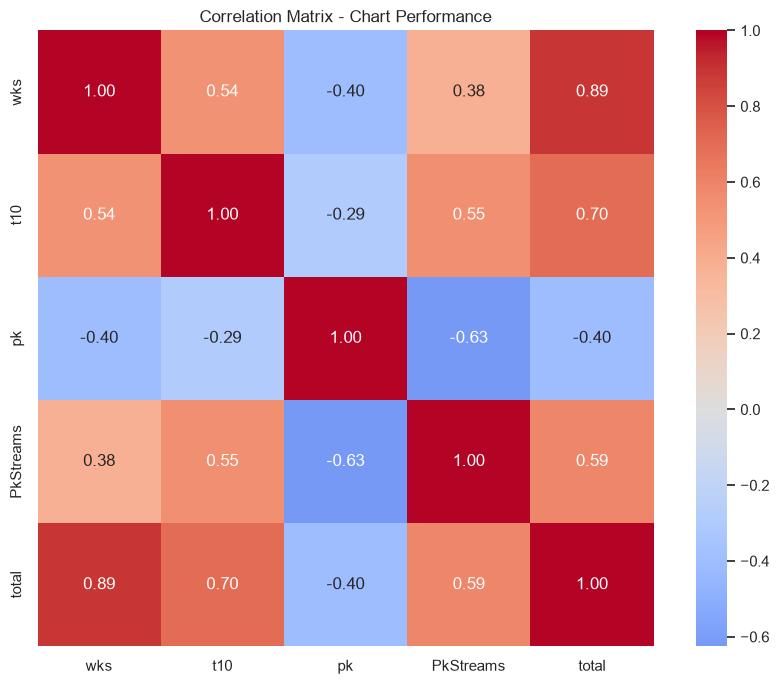

In [28]:
# Visualize

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    square=True,
    cmap="coolwarm",
    center=0 
)


plt.title("Correlation Matrix - Chart Performance")

plt.tight_layout()
plt.show()

Realtionship                      Correlation

wks - total                         0.89
t10 - total                         0.74
PkStreams - total                   0.59
pk - PkStreams                     -0.63
t10 - pk                           -0.58
wks - t10                           0.57



In [30]:
# 20. Artist Representation - Now move from song-level analysis to artist-level analysis.

# TOP ARTISTS BY NUMBER OF CHARTING SONGS

artist_song_counts = (
    df.groupby("artist name")
    .size()
    .sort_values(ascending=False)
)

display(
    artist_song_counts.head(20)
)

artist name
Drake                 248
Taylor Swift          227
Bad Bunny             120
The Weeknd             98
Ariana Grande          96
Eminem                 89
BTS                    86
Kanye West             85
Justin Bieber          82
Kendrick Lamar         77
Ed Sheeran             71
Post Malone            68
Juice WRLD             61
Future                 59
Lil Uzi Vert           59
J. Cole                55
Billie Eilish          55
Tyler, The Creator     55
Travis Scott           54
Lady Gaga              50
dtype: int64

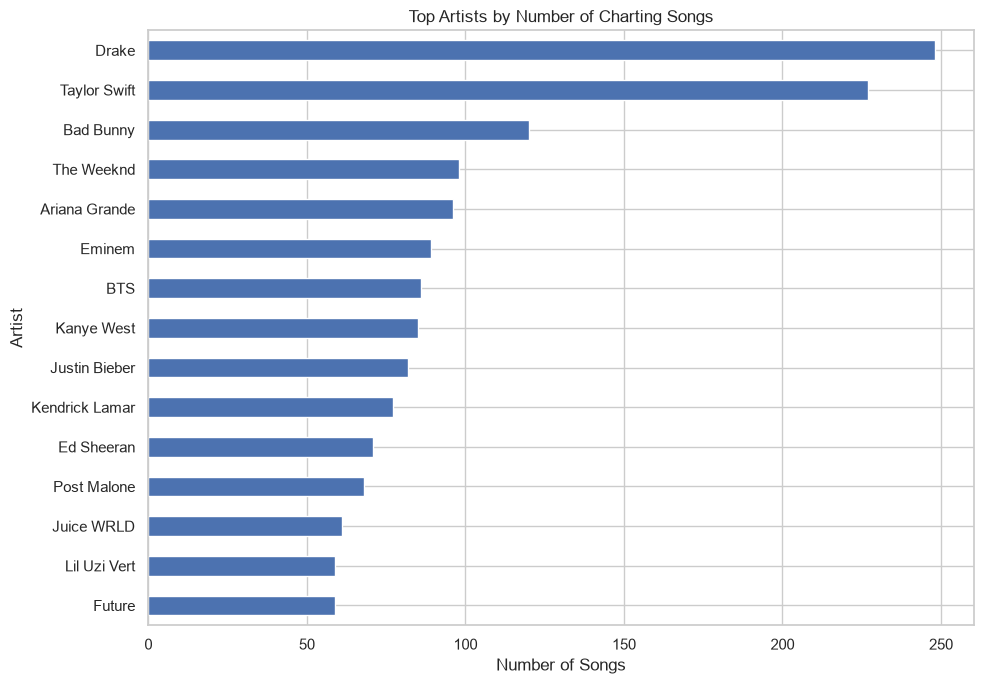

In [31]:
# Plot

top_artists = (
    artist_song_counts
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))

top_artists.plot(
    kind="barh"
)

plt.title("Top Artists by Number of Charting Songs")
plt.xlabel("Number of Songs")
plt.ylabel("Artist")

plt.tight_layout()
plt.show()

In [32]:
# 21. Artist contribution to total streams
# Number of songs is not the same as streaming success.abs

# Calculate total streams by artist:

artist_streams = (
    df.groupby("artist name")
    .agg(
        songs=("song name", "nunique"),
        total_streams= ("total", "sum"),
        median_streams= ("total", "median"),
        mean_weeks = ("wks", "mean")
    )
    .sort_values(
        "total_streams",
        ascending=False
    )
)

display(
    artist_streams.head(20)
)

,songs,total_streams,median_streams,mean_weeks
artist name,,,,
Bad Bunny,120,31134387025,77444100.5,18.675000
The Weeknd,88,29875176511,28839470.0,28.010204
Taylor Swift,215,26273874386,31220010.0,8.224670
Drake,246,22740546162,22343369.5,10.415323
Billie Eilish,53,21972201869,122634392.0,33.163636
Ed Sheeran,66,21777307945,40819170.0,38.239437
Post Malone,66,19237721490,59593759.5,27.852941
Ariana Grande,95,15600211489,33789754.5,15.562500
Justin Bieber,80,13990423095,26085045.5,16.341463


In [33]:
# 22. Artist with multiple charting songs. Filter artists with at least 5 songs


# MULTI-SONG ARTISTS

multi_song_artists = artist_streams[
    artist_streams["songs"] >= 5
].copy()

display(
    multi_song_artists.head(20)
)

,songs,total_streams,median_streams,mean_weeks
artist name,,,,
Bad Bunny,120,31134387025,77444100.5,18.675000
The Weeknd,88,29875176511,28839470.0,28.010204
Taylor Swift,215,26273874386,31220010.0,8.224670
Drake,246,22740546162,22343369.5,10.415323
Billie Eilish,53,21972201869,122634392.0,33.163636
Ed Sheeran,66,21777307945,40819170.0,38.239437
Post Malone,66,19237721490,59593759.5,27.852941
Ariana Grande,95,15600211489,33789754.5,15.562500
Justin Bieber,80,13990423095,26085045.5,16.341463


This prevents artists with one extremely large song from being directly compared with artists having dozens of chart entries.

In [34]:
# 23. Artist concentration - Let's measure how much of the dataset's charting-song representation comes from the top artists

# ARTIST CONCENTRATION

artist_song_counts_sorted = (
    artist_song_counts
    .sort_values(ascending=False)
    .reset_index(name="song_count")
)

artist_song_counts_sorted["cumulative_songs"] = (
    artist_song_counts_sorted["song_count"]
    .cumsum()
)

artist_song_counts_sorted["cumulative_percentage"] = (
    artist_song_counts_sorted["cumulative_songs"]
    / artist_song_counts_sorted["song_count"].sum()
    * 100
)

display(
    artist_song_counts_sorted.head(20)
    
)

,artist name,song_count,cumulative_songs,cumulative_percentage
0,Drake,248,248,3.078451
1,Taylor Swift,227,475,5.896226
2,Bad Bunny,120,595,7.385799
3,The Weeknd,98,693,8.602284
4,Ariana Grande,96,789,9.793942
5,Eminem,89,878,10.898709
6,BTS,86,964,11.966236
7,Kanye West,85,1049,13.021351
8,Justin Bieber,82,1131,14.039225
9,Kendrick Lamar,77,1208,14.995035


In [35]:
# 24. Top artists share

for n in [10, 25, 50, 100]:

    share = (
        artist_song_counts_sorted
        .head(n)["song_count"]
        .sum()
        / len(df)
        * 100
    )


    print(
        f"Top {n} artists account for "
        f"{share:.2f}% of chart records."
    )

Top 10 artists account for 14.99% of chart records.
Top 25 artists account for 25.13% of chart records.
Top 50 artists account for 35.60% of chart records.
Top 100 artists account for 49.52% of chart records.


This is a strong portfolio insight because it quantifies concentration rather than simply listing popular artists.

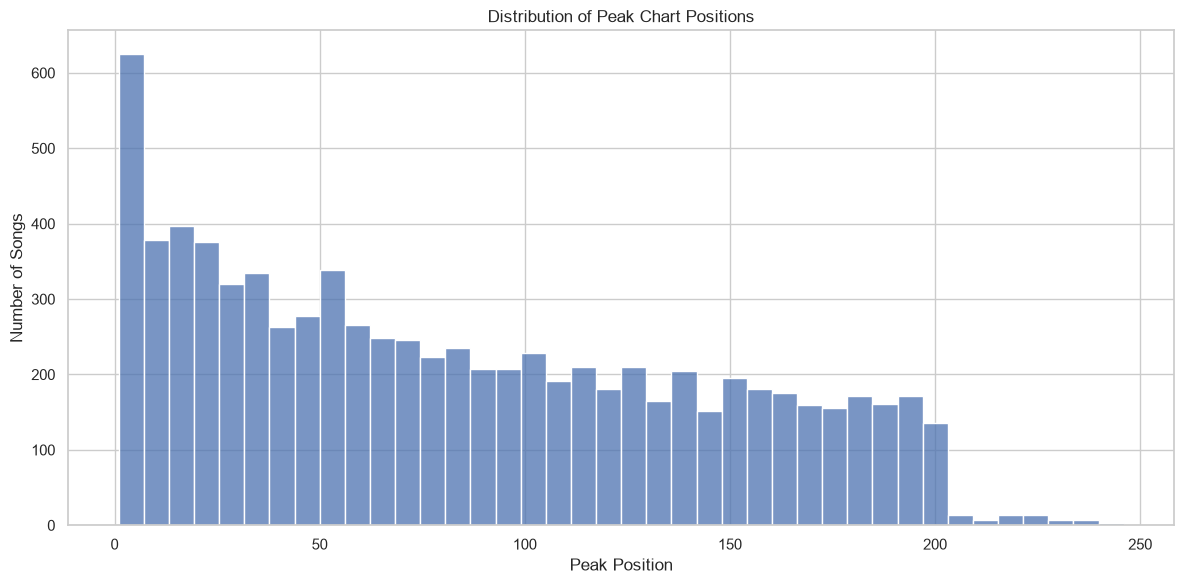

In [36]:
# 25. Distribution of peak position

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="pk",
    bins=40 
)

plt.title("Distribution of Peak Chart Positions")
plt.xlabel("Peak Position")
plt.ylabel("Number of Songs")

plt.tight_layout()
plt.show()

pk = 1 -> highest peak
pk = 246 -> lower peak within this dataset

In [37]:
# 26. Top 10 peak-position breakdown

peak_position_counts = (
    df[df["pk"] <= 10]["pk"]
    .value_counts()
    .sort_index()
)

display(peak_position_counts)

pk
1     134
2     111
3      89
4      72
5      70
6      80
7      69
8      52
9      74
10     59
Name: count, dtype: int64

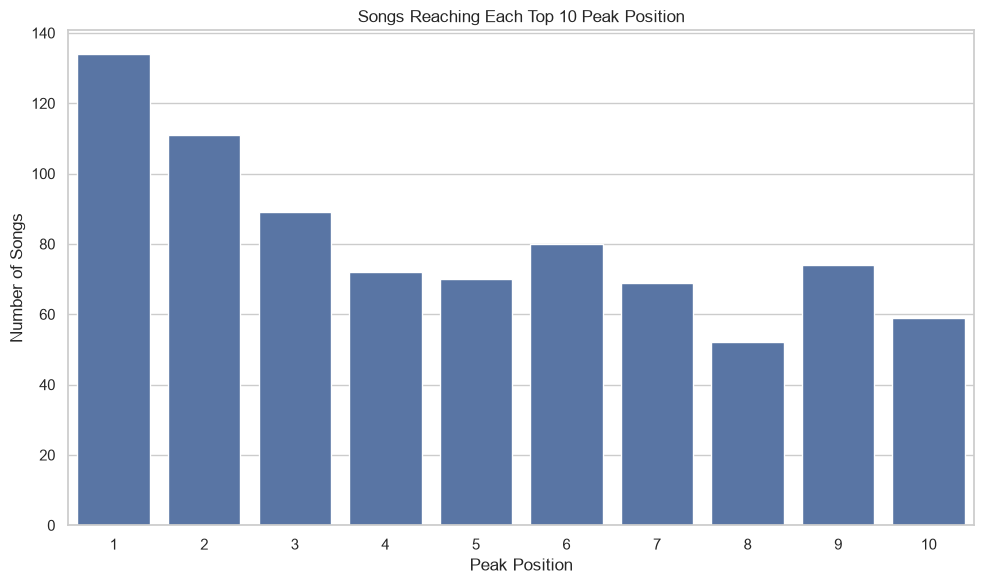

In [38]:
# Plot

plt.figure(figsize=(10, 6))

sns.barplot(
    x=peak_position_counts.index,
    y=peak_position_counts.values
)

plt.title("Songs Reaching Each Top 10 Peak Position")
plt.xlabel("Peak Position")
plt.ylabel("Number of Songs")

plt.tight_layout()
plt.show()

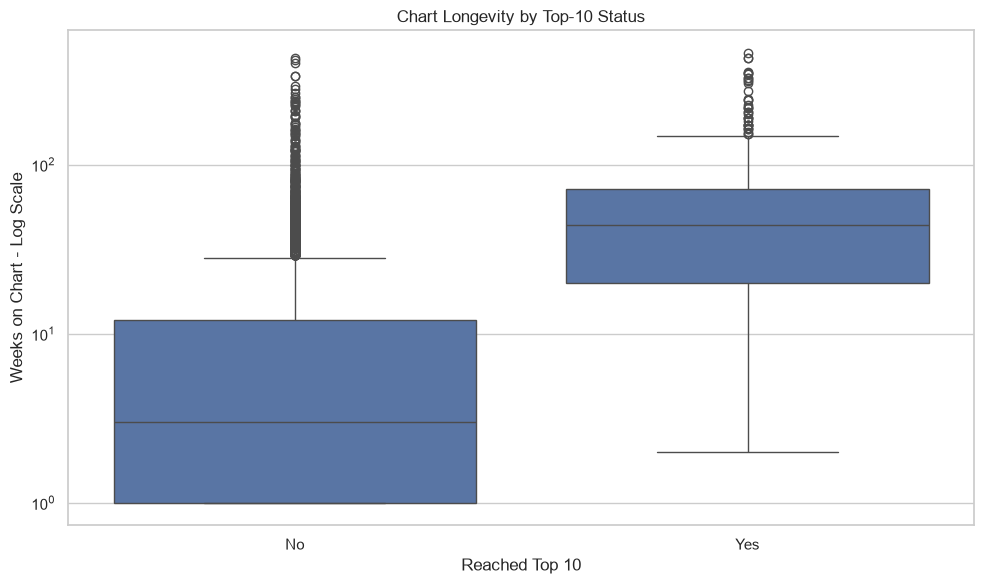

In [39]:
# 27. Relationship between Top-10 status and longevity

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="top10_reached",
    y="wks"
)

plt.yscale("log")

plt.title("Chart Longevity by Top-10 Status")
plt.xlabel("Reached Top 10")
plt.ylabel("Weeks on Chart - Log Scale")


plt.xticks(
    [0, 1],
    ["No", "Yes"]
)

plt.tight_layout()
plt.show()

This is a useful visual for the question:

Are Top-10 songs also associated with longer chart presence?

Again, describe the observed distributions rather than interpreting the relationship casually.

In [40]:
# 28. Extreme-performing songs
# The dataset contains a long tail of exceptionally successful songs. 

# Let's identify the top records by total streams.

# TOP SONGS BY TOTAL STREAMS

top_songs = (
    df[
        [
            "artist name",
            "song name",
            "wks",
            "t10",
            "pk",
            "PkStreams",
            "total"
        ]
    ]
    .sort_values(
        "total",
        ascending=False
    )
    .head(20)
)

display(top_songs)



,artist name,song name,wks,t10,pk,PkStreams,total
0,The Weeknd,Blinding Lights,347,64,1,52375259,5441240333
1,Ed Sheeran,Shape of You,424,34,1,64217796,4470842634
2,Harry Styles,As It Was,218,60,1,78460903,4417264164
3,The Neighbourhood,Sweater Weather,333,0,16,21624450,4142643719
4,Lewis Capaldi,Someone You Loved,343,15,4,24962682,3933581891
5,The Weeknd,Starboy,317,21,1,35360281,3857210959
6,Billie Eilish,BIRDS OF A FEATHER,114,71,1,66726270,3821072735
7,Lady Gaga,Die With A Smile,101,61,1,78624101,3797546382
8,Post Malone,Sunflower,346,31,1,34579416,3793341693
9,Ed Sheeran,Perfect,457,15,4,24763619,3730229095


In [41]:
# 29 . Top songs by Longevity 

longest_charting = (
    df[
        [
            "artist name",
            "song name",
            "wks",
            "t10",
            "pk",
            "PkStreams",
            "total"
        ]
    ]
    .sort_values(
        "wks",
        ascending=False
    )
    .head(20)
)

display(longest_charting)

,artist name,song name,wks,t10,pk,PkStreams,total
9,Ed Sheeran,Perfect,457,15,4,24763619,3730229095
14,Imagine Dragons,Believer,425,0,16,16864827,3353483545
1,Ed Sheeran,Shape of You,424,34,1,64217796,4470842634
22,OneRepublic,Counting Stars,424,24,3,11170130,2739753518
20,Vance Joy,Riptide,415,0,16,16836644,2983453847
10,Billie Eilish,lovely,400,0,24,14081242,3514154790
30,James Arthur,Say You Won't Let Go,352,15,7,19297939,2581216939
0,The Weeknd,Blinding Lights,347,64,1,52375259,5441240333
8,Post Malone,Sunflower,346,31,1,34579416,3793341693
4,Lewis Capaldi,Someone You Loved,343,15,4,24962682,3933581891


This gives a different definition of success:

Streaming success ≠ Longevity 

That distinction will become important later.

In [42]:
# 30. Top songs by peak streams.

top_peak_streams = (
    df[
        [
            "artist name",
            "song name",
            "pk",
            "PkStreams",
            "wks",
            "total"
        ]
    ]
    .sort_values(
        "PkStreams",
        ascending=False
    )
    .head(20)
)


display(top_peak_streams)

,artist name,song name,pk,PkStreams,wks,total
104,Taylor Swift,The Fate of Ophelia,1,128896137,42,1520442009
36,Miley Cyrus,Flowers,1,115156896,115,2459389429
340,Taylor Swift,Fortnight,1,102878399,34,757105267
309,Taylor Swift,Opalite,2,93572415,41,797146057
47,Mariah Carey,All I Want for Christmas Is You,1,92506541,92,2117164649
75,Wham!,Last Christmas,1,91090914,87,1815281512
21,Jung Kook,Seven,1,89748171,156,2809494264
56,Bad Bunny,DtMF,1,88786254,81,2025045584
34,ROSÉ,APT.,1,87041494,92,2484667419
1215,Taylor Swift,Elizabeth Taylor,3,85348366,9,233721100


In [44]:
# 31. Lyrics availability comparison
# Now connect the EDA with the later NLP work.

# LYRICS AVAILABILITY ANALYSIS

lyrics_comparison = (
    df.groupby("lyrics_available")
    .agg(
        songs=("song name", "count"),
        median_wks=("wks", "median"),
        median_total=("total", "median"),
        median_pk_streams=("PkStreams", "median")
    )
)

lyrics_comparison.index = [
    "Lyrics Unavailable",
    "Lyrics Available"
]

display(lyrics_comparison)

,songs,median_wks,median_total,median_pk_streams
Lyrics Unavailable,15,1.0,7734674.0,6118256.0
Lyrics Available,8043,4.0,28075943.0,8946687.0


Because only 15 records lack lyrics, don't overinterpret differences between these groups.

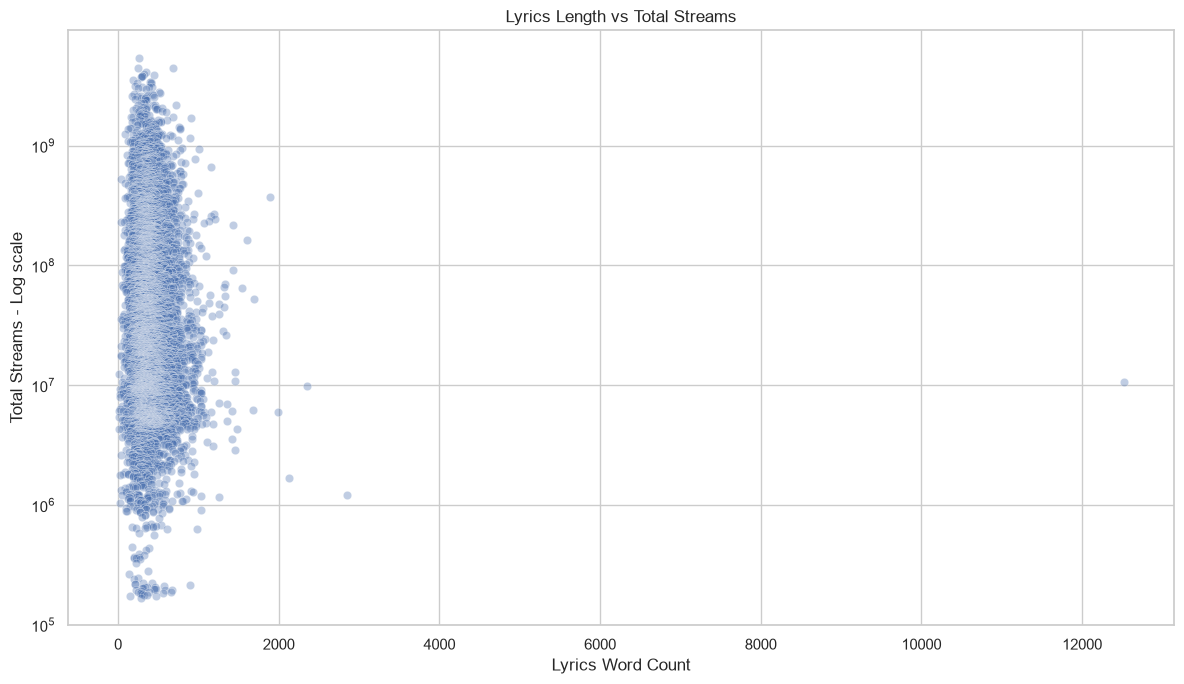

In [45]:
# 32. Lyrics length vs chart performance 

lyrics_df = df[
    df["lyrics_available"]
    & (df["lyrics_word_count"] > 0)
].copy()

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=lyrics_df,
    x="lyrics_word_count",
    y="total",
    alpha=0.35
)

plt.yscale("log")

plt.title("Lyrics Length vs Total Streams")
plt.xlabel("Lyrics Word Count")
plt.ylabel("Total Streams - Log scale")

plt.tight_layout()
plt.show()

Do not include that lyric length causes streaming success. This is exploratory association only.

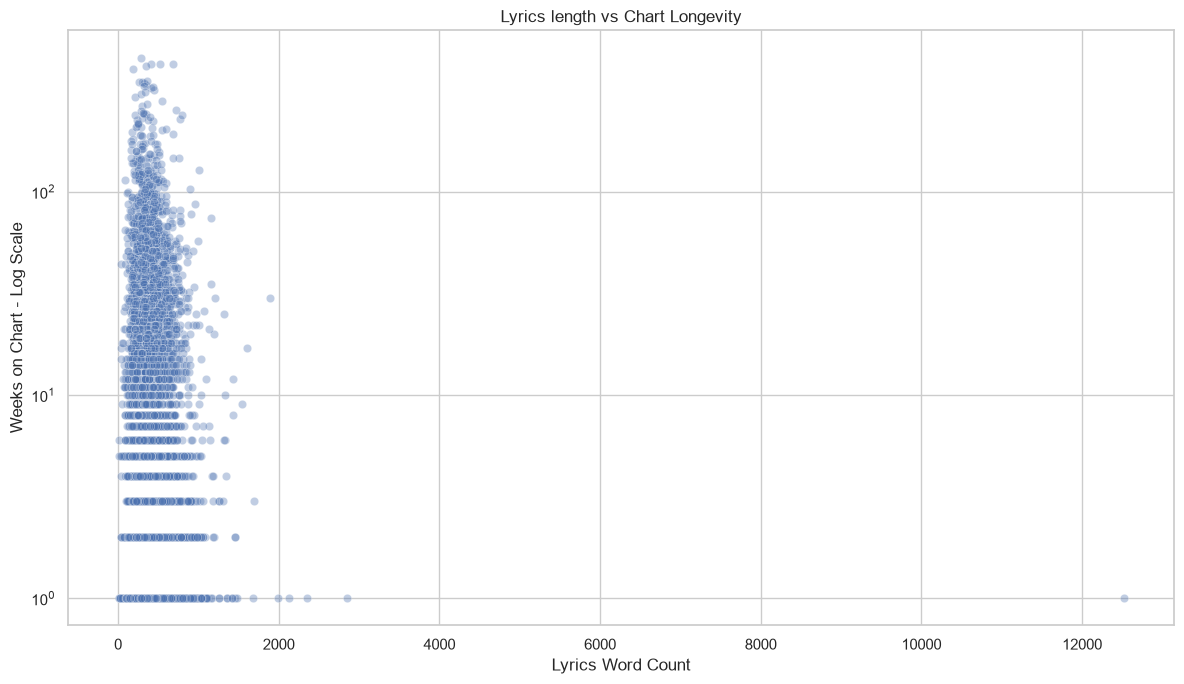

In [46]:
# 33. Lyrics length vs longevity

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=lyrics_df,
    x="lyrics_word_count",
    y="wks",
    alpha=0.35
)

plt.yscale("log")

plt.title("Lyrics length vs Chart Longevity")
plt.xlabel("Lyrics Word Count")
plt.ylabel("Weeks on Chart - Log Scale")

plt.tight_layout()
plt.show()

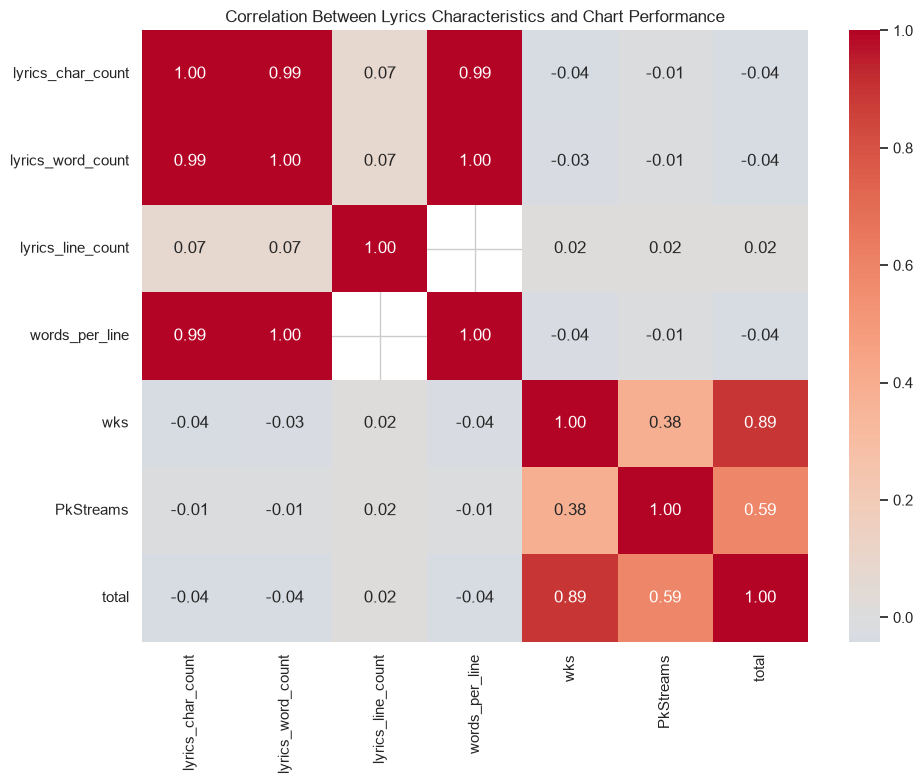

In [47]:
# 34. Correlation including lyric features

# LYRICS + PERFORMANCE CORRELATIONS

lyrics_corr_cols = [
        "lyrics_char_count",
        "lyrics_word_count",
        "lyrics_line_count",
        "words_per_line",
        "wks",
        "PkStreams",
        "total"
]

lyrics_corr = (
    df[lyrics_corr_cols]
    .corr()
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    lyrics_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Between Lyrics Characteristics "
    "and Chart Performance"
)


plt.tight_layout()
plt.show()

In [49]:
# 35. Identify high-performance songs
# Instead of relying only on one metric, use your previously created outlier flags.

# EXTREME PERFORMANCE ANALYSIS

extreme_summary = (
    df["extreme_performance_count"]
    .value_counts()
    .sort_index()
)


display(extreme_summary)

extreme_performance_count
0    6744
1     542
2     534
3     221
4      17
Name: count, dtype: int64

In [50]:
# Then

high_performance_songs = df[
    df["extreme_performance_count"] >= 2
].copy()

print(
    "Songs flagged as extreme on at least two "
    f"performance dimensions: {len(high_performance_songs):,}"
)

Songs flagged as extreme on at least two performance dimensions: 772


In [53]:
# 36. Compare extreme vs typical songs

extreme_comparison = (
    df.assign(
        performance_group=np.where(
            df["extreme_performance_count"] >= 2,
            "Extreme Performance",
            "Other Songs"
        )
    )
    .groupby("performance_group")
    .agg(
        songs=("song name", "count"),
        median_wks=("wks", "median"),
        median_t10=("t10", "median"),
        median_pk=("pk", "median"),
        median_peak_streams=("PkStreams", "median"),
        median_total=("total", "median")
    )
)

display(extreme_comparison)

,songs,median_wks,median_t10,median_pk,median_peak_streams,median_total
performance_group,,,,,,
Extreme Performance,772,63.0,3.0,6.0,24810516.5,680385124.0
Other Songs,7286,3.0,0.0,83.0,8313971.0,22105665.5


In [ ]:
# 37. Save important EDA tables - Create an output tables directory:

# OUTPUT TABLES

TABLE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

In [55]:
# Save the most useful outputs:

performance_stats.to_csv(
    TABLE_DIR / "performance_descriptive_statistics.csv"
)

top10_summary.to_csv(
    TABLE_DIR / "top10_comparison.csv"
)

artist_streams.head(100).to_csv(
    TABLE_DIR / "top_artists_by_streams.csv"
)

artist_song_counts_sorted.head(100).to_csv(
    TABLE_DIR / "top_artists_by_song_count.csv"
)

top_songs.to_csv(
    TABLE_DIR / "top_songs_by_total_streams.csv",
    index=False 
)

longest_charting.to_csv(
    TABLE_DIR / "longest_charting_songs.csv",
    index=False 
)


top_peak_streams.to_csv(
    TABLE_DIR / "top_songs_by_peak_streams.csv",
    index=False
)


print("EDA tables saved successfully.")

EDA tables saved successfully.


In [60]:
# Check the current working directory

import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
c:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\notebook


In [62]:
from pathlib import Path 

print("Current directory contents:")
print(list(Path.cwd().iterdir())[:20])

Current directory contents:
[WindowsPath('c:/Users/Sanu/OneDrive/Desktop/Spotify-Global-Hit-Intelligence/notebook/01_Data_Understanding.ipynb'), WindowsPath('c:/Users/Sanu/OneDrive/Desktop/Spotify-Global-Hit-Intelligence/notebook/02_Data_Quality_and_Preprocessing.ipynb'), WindowsPath('c:/Users/Sanu/OneDrive/Desktop/Spotify-Global-Hit-Intelligence/notebook/03_Exploratory_Data_Analysis.ipynb')]


In [65]:
# PROJECT PATH SETUP - WINDOWS

from pathlib import Path 

PROJECT_ROOT = Path(
    r"C:\Users\Sanu\OneDrive\Desktop\Spotify-Globa;-Hit-Intelligence" 
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_global_chart_totals_lyrics_cleaned.csv"
)


OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
)

# Create output directories
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True 
)

print("Project root:")
print(PROJECT_ROOT)

print("\nDataset:")
print(DATA_PATH)

print("\nDataset exists:", DATA_PATH.exists())

print("\nFigures Directory")
print(OUTPUT_DIR)

print("\nFigures directory exists:", OUTPUT_DIR.exists())

print("\nTables directory:")
print(TABLE_DIR)

print("\nTables directory exists:", TABLE_DIR.exists())




Project root:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Globa;-Hit-Intelligence

Dataset:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Globa;-Hit-Intelligence\data\processed\spotify_global_chart_totals_lyrics_cleaned.csv

Dataset exists: False

Figures Directory
C:\Users\Sanu\OneDrive\Desktop\Spotify-Globa;-Hit-Intelligence\outputs\tables

Figures directory exists: True

Tables directory:
..\outputs\tables

Tables directory exists: True


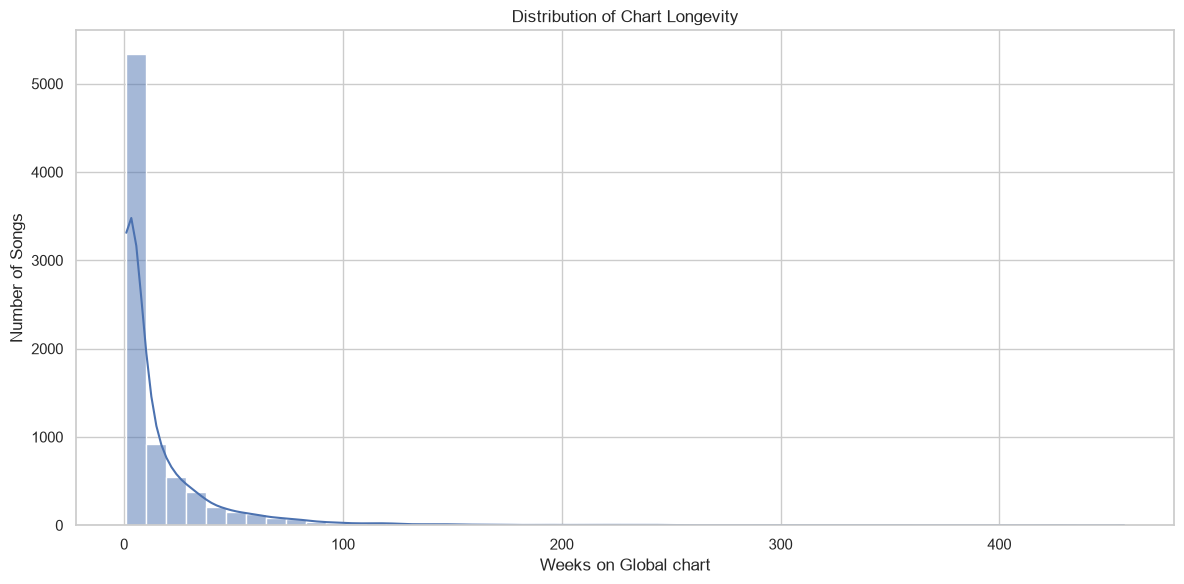

Saved successfully:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Globa;-Hit-Intelligence\outputs\tables\chart_longevity_distribution.png

File exists: True


In [ ]:
# 38. Test the figure save - Now recreate the longevity plot and save it:

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="wks",
    bins=50,
    kde=True
)

plt.title("Distribution of Chart Longevity")
plt.xlabel("Weeks on Global chart")
plt.ylabel("Number of Songs")

plt.tight_layout()

figure_path = (
    OUTPUT_DIR /
    "chart_longevity_distribution.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Saved successfully:")
print(figure_path)

print("\nFile exists:", figure_path.exists())

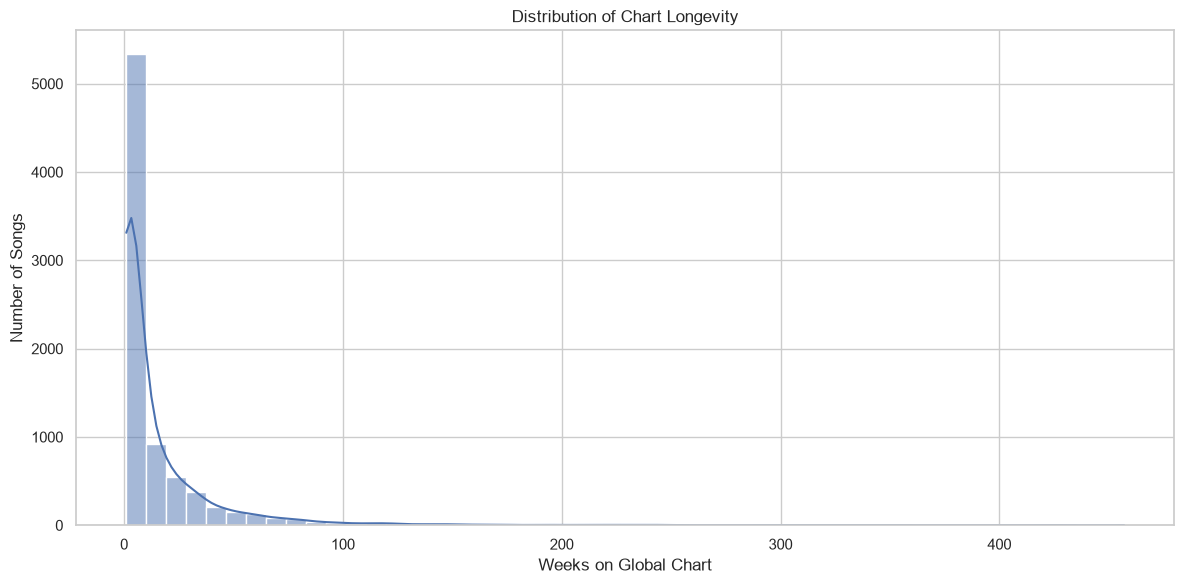

In [68]:
# Save important figures

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="wks",
    bins=50,
    kde=True
)

plt.title("Distribution of Chart Longevity")
plt.xlabel("Weeks on Global Chart")
plt.ylabel("Number of Songs")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "chart_longevity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [72]:
# 39. Final EDA insight table

# At the end, create a compact machine-readable summary

eda_insights = pd.DataFrame({
        "Metric": 
            [
                "Total Songs",
                "Unique Songs",
                "Unique Artists",
                "Top-10 Reach Rate (%)",
                "Median Chart Weeks",
                "Mean Chart Weeks",
                "Median Total Streams",
                "Mean Peak Streams",
                "Median Peak Position",
                "Median Lyrics Word Count"
            ],

            "Value": [
                len(df),
                df["song name"].nunique(),
                df["artist name"].nunique(),
                df["top10_reached"].mean() * 100,
                df["wks"].median(),
                df["wks"].mean(),
                df["total"].median(),
                df["PkStreams"].median(),
                df["pk"].median(),
                df.loc[
                    df["lyrics_available"],
                    "lyrics_word_count"
                ].median()
            ]
        
    })

display(eda_insights)

,Metric,Value
0,Total Songs,8.058000e+03
1,Unique Songs,7.277000e+03
2,Unique Artists,1.793000e+03
3,Top-10 Reach Rate (%),1.005212e+01
4,Median Chart Weeks,4.000000e+00
5,Mean Chart Weeks,1.551055e+01
6,Median Total Streams,2.798093e+07
7,Mean Peak Streams,8.941470e+06
8,Median Peak Position,7.400000e+01
9,Median Lyrics Word Count,3.700000e+02


In [73]:
# Save

eda_insights.to_csv(
    TABLE_DIR / "eda_summary_metrics.csv",
    index=False
)

### EDA Conclusions

1. Chart Longevity 

Chart presence is highly right-skewed. Most songs have relatively short chart runs, while a smaller number of songs remain on the global chart for substantially longer periods.

2. Streaming Concentration

Total streams are strongly right-skewed, indicating that a relatively small number of songs account for exceptionally large streaming volumes.

3. Longevity and Streaming

Chart weeks and total streams show a strong positive association. Songs with longer chart presence generally accumulate substantially higher lifetime streams.

This is an observed association and should not be interpreted as a causal relationship.

4. Top-10 Performance 

Top-10 songs represent a minority of the dataset. Songs reaching the Top 10 show different distributions of chart longevity and streaming 
performance compared with songs that never reached the Top 10.

5. Peak Position

Lower peak-position values are associated with higher peak streaming levels. This is consistent with the interpretation that songs reaching higher chart positions also tend to have stronger peak streaming performance.

6. Artist Concentration

Chart representation is concentrated among a subset of artists. Several artists appear with substantially more charting songs than the typical artist.

7. Extreme Performers

The dataset contains genuine extreme observations representing major global hits. These observations were retained rather than removed as
erroneous outliers.

8. Lyrics

Lyrics are available for the large majority of songs. Initial lyric-length analysis provides useful hypotheses for the dedicated NLP analysis.

9. Next Analytical Stage

The EDA establishes several hypotheses for the subsequent analysis:

- What linguistic characteristics distinguish highly successful songs?
- Are lyric themes associated with chart longevity?
- Can songs be segmented according to chart-performance profiles?
- Which features explain difference in success?
- Can early chart information be used to predict future performance?

These questions will be investigated using NLP, feature engineering, segmentation, predictive modeling and explainability in subsequent notbooks.
 

The Key distinction for the project

1 Data Understanding

2. Data Quality and Preprocessing

3. Exploratory Data Analysis

4. Chart Performance Analysis

5. Artist Analytics

6. Lyrics NLP

7. Feature Engineering

8. Hit Segmentation

9. Machine ELarning

10. Model Comparison

11. SHAP Explainability

12. Final Insights